# Weather API join (scratch)

Start of the Open-Meteo join for Question 3. Hurricane Helene made landfall on the Florida Big Bend late on **September 26, 2024**. Sales in `walmart_transactions.csv` cover September 2024.

**API:** [Open-Meteo Historical Weather](https://open-meteo.com/en/docs/historical-weather-api). No key.

Base URL: `https://archive-api.open-meteo.com/v1/archive`

This notebook only does the cleaning the join needs: store ids and timestamps. Prices, quantities, SKUs, and categories stay untouched.

## Decisions for this join

- **Timezone.** Sales timestamps have no offset. The project brief treats them as Eastern. Every API call uses `timezone=America/New_York`, so each weather `date` is an Eastern calendar day and can merge to `timestamp` cut back to midnight. Pensacola is in Central time in real life. We still request Eastern time so the dates match the sales file. Revisit that if store-level timing starts to matter.
- **Grain.** One weather row per store per day, joined to one sales row per store per day. A left join keeps every sales day.
- **Missing coordinates.** `FL-619` (Tallahassee) has blank latitude and longitude. Those come from the Open-Meteo geocoding API, not a typed-in guess. The column `coord_source` says which rows used that lookup.
- **What an order is.** One transaction row after exact duplicates and rows with no timestamp are dropped. Quantity is not cleaned yet, so `orders` counts those rows, not units sold.

In [1]:
from pathlib import Path
import time

import pandas as pd
import requests
import matplotlib.pyplot as plt

BASE = 'https://archive-api.open-meteo.com/v1/archive'
GEOCODE = 'https://geocoding-api.open-meteo.com/v1/search'
RETRY_STATUSES = {429, 500, 502, 503, 504}
LANDFALL = pd.Timestamp('2024-09-26')
START, END = '2024-09-01', '2024-09-30'

def find_repo():
    here = Path.cwd()
    for folder in [here, here.parent, here.parent.parent]:
        if (folder / 'data' / 'walmart_transactions.csv').exists():
            return folder
    raise FileNotFoundError('could not find data/walmart_transactions.csv')

REPO = find_repo()
print('repo:', REPO)

repo: /Users/amudh/Documents/Walmart_Hurricane_Project/ds2002_walmart_hurricane_project


## Load the files

In [2]:
transactions = pd.read_csv(REPO / 'data' / 'walmart_transactions.csv')
stores_raw = pd.read_csv(REPO / 'data' / 'store_locations.csv')

print('transactions:', transactions.shape)
print('stores:', stores_raw.shape)
stores_raw[['store_id', 'city', 'latitude', 'longitude']]

transactions: (25562, 8)
stores: (14, 8)


,store_id,city,latitude,longitude
0,FL-239,Orlando,28.5383,-81.3792
1,FL-105,Tampa,27.9506,-82.4572
2,FL-330,Miami,25.7617,-80.1918
3,FL-412,Jacksonville,30.3322,-81.6557
4,FL-287,Kissimmee,28.2920,-81.4076
5,FL-156,Daytona Beach,29.2108,-81.0228
6,FL-501,Fort Myers,26.6406,-81.8723
7,FL-078,Gainesville,29.6516,-82.3248
8,FL-619,Tallahassee,NaN,NaN
9,FL-445,St. Petersburg,27.7676,-82.6403


## Store ids and coordinates

The table above is the store file. Orlando is in there twice, as `FL-239` and `FL239`. Kissimmee is in there twice, as `FL-287` and `FL_287`.

The other spellings are in the transactions, not in that table. Orlando alone shows up there as `FL-239`, `FL239`, `FL_239`, `fl-239`, and ` FL-239`.

In [3]:
def canonical_store_id(value):
    text = str(value).strip().upper().replace('_', '').replace(' ', '')
    if text.startswith('FL') and text[2:].isdigit():
        return f'FL-{text[2:]}'
    return text

stores = stores_raw.copy()
stores['store_id'] = stores['store_id'].map(canonical_store_id)
stores = stores.drop_duplicates(subset='store_id', keep='first').reset_index(drop=True)
stores['coord_source'] = 'store file'
print(stores['store_id'].tolist())
print('stores missing coordinates:', int(stores['latitude'].isna().sum()))

['FL-239', 'FL-105', 'FL-330', 'FL-412', 'FL-287', 'FL-156', 'FL-501', 'FL-078', 'FL-619', 'FL-445', 'FL-302', 'FL-710']
stores missing coordinates: 1


In [4]:
def geocode_city(name, admin='Florida'):
    """Look up a US city. Returns latitude, longitude from Open-Meteo."""
    response = requests.get(
        GEOCODE,
        params={'name': name, 'count': 5, 'countryCode': 'US'},
        timeout=10,
    )
    response.raise_for_status()
    for item in response.json().get('results', []):
        if item.get('admin1') == admin and item.get('name', '').lower() == name.lower():
            return float(item['latitude']), float(item['longitude'])
    raise LookupError(f'no geocode hit for {name}, {admin}')

missing = stores['latitude'].isna() | stores['longitude'].isna()
for idx in stores.index[missing]:
    lat, lon = geocode_city(stores.at[idx, 'city'])
    stores.at[idx, 'latitude'] = lat
    stores.at[idx, 'longitude'] = lon
    stores.at[idx, 'coord_source'] = 'open-meteo geocoding'
    print(stores.at[idx, 'store_id'], stores.at[idx, 'city'], lat, lon)

stores[['store_id', 'city', 'latitude', 'longitude', 'coord_source']]

FL-619 Tallahassee 30.43826 -84.28073


,store_id,city,latitude,longitude,coord_source
0,FL-239,Orlando,28.53830,-81.37920,store file
1,FL-105,Tampa,27.95060,-82.45720,store file
2,FL-330,Miami,25.76170,-80.19180,store file
3,FL-412,Jacksonville,30.33220,-81.65570,store file
4,FL-287,Kissimmee,28.29200,-81.40760,store file
5,FL-156,Daytona Beach,29.21080,-81.02280,store file
6,FL-501,Fort Myers,26.64060,-81.87230,store file
7,FL-078,Gainesville,29.65160,-82.32480,store file
8,FL-619,Tallahassee,30.43826,-84.28073,open-meteo geocoding
9,FL-445,St. Petersburg,27.76760,-82.64030,store file


## Daily orders

A timestamp like `2024-09-26 08:52` does not equal a weather date of `2024-09-26`. The join key is the timestamp cut back to midnight.

In [5]:
sales = transactions.copy()
n_raw = len(sales)
n_dupes = int(sales.duplicated().sum())
sales = sales.drop_duplicates()
sales['store_id'] = sales['store_id'].map(canonical_store_id)
sales['timestamp'] = pd.to_datetime(sales['timestamp'], errors='coerce', format='mixed')
n_bad_time = int(sales['timestamp'].isna().sum())
sales = sales.dropna(subset=['timestamp'])
sales['date'] = sales['timestamp'].dt.normalize()

unknown = sorted(set(sales['store_id']) - set(stores['store_id']))
if unknown:
    raise ValueError(f'store ids with no location: {unknown}')

daily_orders = (
    sales.groupby(['store_id', 'date'], as_index=False)
    .size()
    .rename(columns={'size': 'orders'})
)

print(f'rows in file: {n_raw:,}')
print(f'exact duplicate rows dropped: {n_dupes:,}')
print(f'rows with no parseable timestamp dropped: {n_bad_time:,}')
print(f'rows kept: {len(sales):,}')
print(f'store-days with orders: {len(daily_orders):,}')
print('date range:', sales['date'].min().date(), 'to', sales['date'].max().date())
daily_orders.head()

rows in file: 25,562
exact duplicate rows dropped: 30
rows with no parseable timestamp dropped: 884
rows kept: 24,648
store-days with orders: 360
date range: 2024-09-01 to 2024-09-30


,store_id,date,orders
0,FL-078,2024-09-01,43
1,FL-078,2024-09-02,49
2,FL-078,2024-09-03,47
3,FL-078,2024-09-04,46
4,FL-078,2024-09-05,43


## Open-Meteo

`daily_weather` retries on a timeout, a dropped connection, or a 429 or 5xx. It converts `time` to a datetime named `date` before anything else can merge on it, and it stamps `source` so a later fallback cannot be mistaken for a live call.

Daily fields, because Question 3 asks for all three:

- `precipitation_sum` (mm)
- `windspeed_10m_max` (km/h)
- `pressure_msl_mean` (hPa), the barometric pressure

In [6]:
def daily_weather(start, end, lat, lon, tries=3):
    """One row per day from Open-Meteo, in Eastern time."""
    params = {
        'latitude': lat,
        'longitude': lon,
        'start_date': start,
        'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max,pressure_msl_mean',
        'timezone': 'America/New_York',
        'wind_speed_unit': 'kmh',
        'precipitation_unit': 'mm',
    }
    for attempt in range(1, tries + 1):
        try:
            response = requests.get(BASE, params=params, timeout=15)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if response.status_code in RETRY_STATUSES:
            if attempt == tries:
                response.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        response.raise_for_status()
        payload = response.json()
        frame = pd.DataFrame(payload['daily'])
        frame = frame.rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])
        frame['source'] = 'open-meteo'
        frame['timezone'] = payload.get('timezone')
        return frame

frames = []
for store in stores.itertuples(index=False):
    frame = daily_weather(START, END, store.latitude, store.longitude)
    frame.insert(0, 'store_id', store.store_id)
    frame.insert(1, 'city', store.city)
    frames.append(frame)

weather = pd.concat(frames, ignore_index=True)
print('source:', weather['source'].unique().tolist())
print('timezone:', weather['timezone'].unique().tolist())
print('weather rows:', len(weather), ' stores:', weather['store_id'].nunique(), ' days:', weather['date'].nunique())
weather.head()

source: ['open-meteo']
timezone: ['America/New_York']
weather rows: 360  stores: 12  days: 30


,store_id,city,date,precipitation_sum,windspeed_10m_max,pressure_msl_mean,source,timezone
0,FL-239,Orlando,2024-09-01,6.4,18.7,1014.1,open-meteo,America/New_York
1,FL-239,Orlando,2024-09-02,22.0,12.7,1014.1,open-meteo,America/New_York
2,FL-239,Orlando,2024-09-03,32.7,20.6,1015.6,open-meteo,America/New_York
3,FL-239,Orlando,2024-09-04,21.1,12.6,1017.7,open-meteo,America/New_York
4,FL-239,Orlando,2024-09-05,20.7,15.2,1017.3,open-meteo,America/New_York


## Checked join

Left join on `store_id` and `date`. Three checks, from the studio recipe:

1. The row count still equals the number of store-days that had sales.
2. No weather-only rows appear (`right_only`). A left join cannot create those unless `how` changes later.
3. The order total is unchanged.

In [7]:
merged = daily_orders.merge(weather, on=['store_id', 'date'], how='left', indicator=True)

assert len(merged) == len(daily_orders), 'the join changed the row count'
assert not (merged['_merge'] == 'right_only').any(), 'weather rows with no sales day'
assert merged['orders'].sum() == daily_orders['orders'].sum(), 'the orders total changed'

print(merged['_merge'].value_counts().to_string())
print()
unmatched = merged.loc[merged['_merge'] == 'left_only', ['store_id', 'date']]
print('sales store-days with no weather:', len(unmatched))
if len(unmatched):
    print(unmatched.head(20).to_string(index=False))
print('all three checks passed')
merged.drop(columns='_merge').head()

_merge
both          360
left_only       0
right_only      0

sales store-days with no weather: 0
all three checks passed


,store_id,date,orders,city,precipitation_sum,windspeed_10m_max,pressure_msl_mean,source,timezone
0,FL-078,2024-09-01,43,Gainesville,1.5,11.3,1014.1,open-meteo,America/New_York
1,FL-078,2024-09-02,49,Gainesville,2.9,8.3,1013.6,open-meteo,America/New_York
2,FL-078,2024-09-03,47,Gainesville,8.0,16.3,1015.8,open-meteo,America/New_York
3,FL-078,2024-09-04,46,Gainesville,15.6,15.3,1018.2,open-meteo,America/New_York
4,FL-078,2024-09-05,43,Gainesville,13.3,13.8,1017.4,open-meteo,America/New_York


## A first look

Add the 12 stores into one row per day: total orders, and the average of each store's max wind. Then look at September 26.

The check is whether the wind peak sits on landfall and the order peak sits just before it. If the join had paired sales with the wrong day, those peaks would miss the line.

This is not the Question 3 answer. It counts transaction rows for the whole state, not units by category. A correlation on only September 23–25 is too thin to report, because three days can produce almost any number.

baseline Sept 1-15: 579 orders/day over 15 days
surge Sept 23-25:   1783 orders/day over 3 days
multiple: 3.1x

orders vs mean max wind 0 day(s) later: r = 0.23  (n = 30)
orders vs mean max wind 1 day(s) later: r = 0.59  (n = 29)
orders vs mean max wind 2 day(s) later: r = 0.81  (n = 28)
orders vs mean max wind 3 day(s) later: r = 0.61  (n = 27)
orders vs mean max wind 4 day(s) later: r = 0.41  (n = 26)


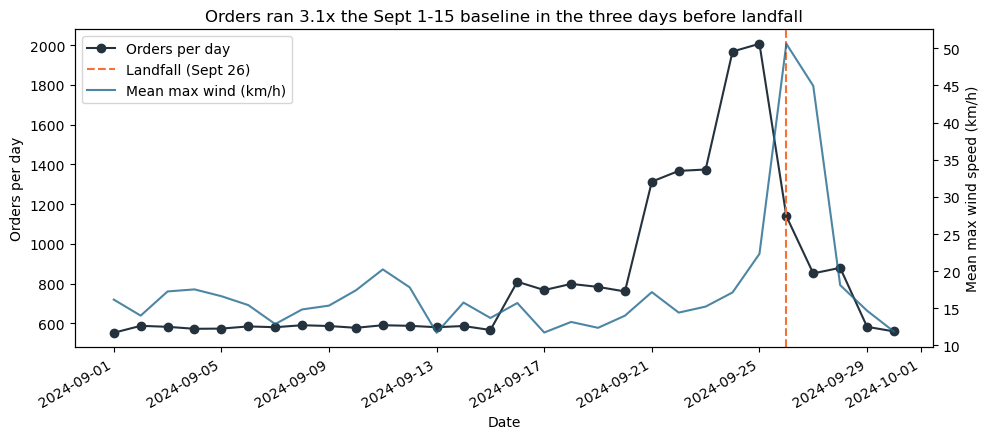

In [8]:
statewide = (
    merged.groupby('date', as_index=False)
    .agg(orders=('orders', 'sum'), windspeed_10m_max=('windspeed_10m_max', 'mean'),
         precipitation_sum=('precipitation_sum', 'mean'), pressure_msl_mean=('pressure_msl_mean', 'mean'))
)

def window(frame, start, end):
    return frame[(frame['date'] >= start) & (frame['date'] <= end)]

baseline = window(statewide, '2024-09-01', '2024-09-15')
surge = window(statewide, '2024-09-23', '2024-09-25')
baseline_per_day = baseline['orders'].mean()
surge_per_day = surge['orders'].mean()
multiple = surge_per_day / baseline_per_day

print(f'baseline Sept 1-15: {baseline_per_day:.0f} orders/day over {len(baseline)} days')
print(f'surge Sept 23-25:   {surge_per_day:.0f} orders/day over {len(surge)} days')
print(f'multiple: {multiple:.1f}x')
print()
for k in range(0, 5):
    r = statewide['orders'].corr(statewide['windspeed_10m_max'].shift(-k))
    print(f'orders vs mean max wind {k} day(s) later: r = {r:.2f}  (n = {len(statewide) - k})')

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(statewide['date'], statewide['orders'], marker='o', color='#24323E', label='Orders per day')
ax.axvline(LANDFALL, color='#F67132', linestyle='--', label='Landfall (Sept 26)')
ax.set_xlabel('Date')
ax.set_ylabel('Orders per day')
ax2 = ax.twinx()
ax2.plot(statewide['date'], statewide['windspeed_10m_max'], color='#21688D', alpha=0.8, label='Mean max wind (km/h)')
ax2.set_ylabel('Mean max wind speed (km/h)')
ax.set_title(f'Orders ran {multiple:.1f}x the Sept 1-15 baseline in the three days before landfall')
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left')
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## Next steps

`orders` is a count of transaction rows. Question 3 wants daily sales volume, which means units sold. After cleaning decides what to do with the 130 negative `quantity` values:

1. Replace `orders` with the sum of `quantity` for that store and day.
2. Split that sum by category. The question asks how weather lines up with volume across categories, so the grain becomes store, date, and category. Weather still joins on store and date, and that day's weather is repeated for each category.
3. Run the same three join checks: row count unchanged, no `right_only` rows, and the quantity total unchanged.
4. Redo the baseline, the lag, and the chart on quantity. The 3.1x and the wind correlations above describe counts of transaction rows, so they are not the Question 3 answer.